In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.image as mpimg
import matplotlib.gridspec as gridspec
import os

from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from PIL import Image

In [2]:
test_dir = '100-bird-species/test/'
train_dir = '100-bird-species/train/'

transformation = transforms.Compose([transforms.Resize((224, 224), Image.LANCZOS), transforms.ToTensor()])
test_data = ImageFolder(test_dir, transform = transformation)
bird_names = test_data.classes

df_accuracies_birds = pd.read_csv('accuracy_per_bird.csv')
df_accuracies_images = pd.read_csv('image_predictions.csv.gz')

number_of_classes = len(bird_names)

In [5]:
print("Number of bird classes with 100% accuracy:", int(np.sum(df_accuracies_birds['Accuracy'] == 1)))

Number of bird classes with 100% accuracy: 76


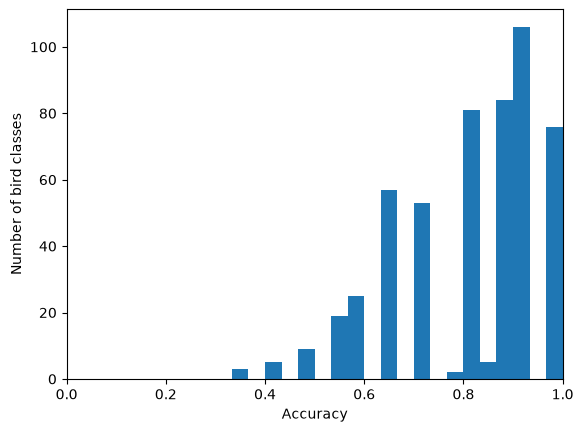

In [6]:
fig, axs = plt.subplots()
axs.hist(df_accuracies_birds['Accuracy'], bins = 20)
axs.set_ylabel('Number of bird classes')
axs.set_xlabel('Accuracy')
axs.set_xlim(0, 1)
plt.show()

In [7]:
perfect_birds = df_accuracies_birds[df_accuracies_birds['Accuracy'] == 1]['Class']
worst_birds = df_accuracies_birds.sort_values(by = 'Accuracy', ascending = True)[:10]['Class']

In [108]:
def get_bird_image_path(bird_class, where = 'test'):
    bird_name = bird_names[bird_class]
    if where == 'test':
        loc = test_dir
    elif where == 'train':
        loc = train_dir
    return loc + bird_name + '/' + os.listdir(loc + bird_name)[0]

def plot_bird_predictions(bird_list, file_name, file_number = 3):
    number_birds = len(bird_list)

    bird_rows = [df_accuracies_images[df_accuracies_images['bird_class'] == bird] for bird in bird_list]

    ##image path
    image_paths = [row['image_path'].iloc[file_number] for row in bird_rows]

    ##getting top 3 preferred birds by the model (in reverse)
    top_predictions = [np.argsort(np.array(row.iloc[file_number][2:]))[-3:] for row in bird_rows]
    prediction_image_paths = [[get_bird_image_path(pred, where = 'train') for pred in top] for top in top_predictions] 

    #results from the model for the top 3 birds
    probabilities= [np.array(row.iloc[file_number][2:])[pred] for pred, row in zip(top_predictions, bird_rows)]

    fig, axs = plt.subplots(number_birds, 4, figsize = (10, 3*number_birds), squeeze = False)
    for i in range(number_birds):
        #plotting the image
        axs[i,0].imshow(mpimg.imread(image_paths[i]))
        axs[i,0].set_title(bird_list.iloc[i])

        for j in range(3):
            axs[i,j+1].imshow(mpimg.imread(prediction_image_paths[i][-1-j]))
            axs[i,j+1].set_title(f"{bird_names[top_predictions[i][-1-j]]}\n{probabilities[i][-1-j]:.5%}", fontsize = 8)

    #removing all axes:
    for a in axs.flat:
        a.axis('off')

    plt.tight_layout()

    for i in range(number_birds - 1):
        y = axs[i,0].get_position().y0
        fig.add_artist(plt.Line2D((0, 1), (y, y), color = 'black', linewidth = 3))

    fig.add_artist(plt.Line2D((0.25, 0.25), (0, 1.05), color = 'black', linewidth = 3))

    plt.figtext(0.125, 1.01, 'Sample from\ntest set', ha = 'center', fontsize = 16)
    plt.figtext(0.625, 1.01, 'Predictions', ha = 'center', fontsize = 16)

    plt.savefig(file_name, bbox_inches = 'tight') 

    plt.show()

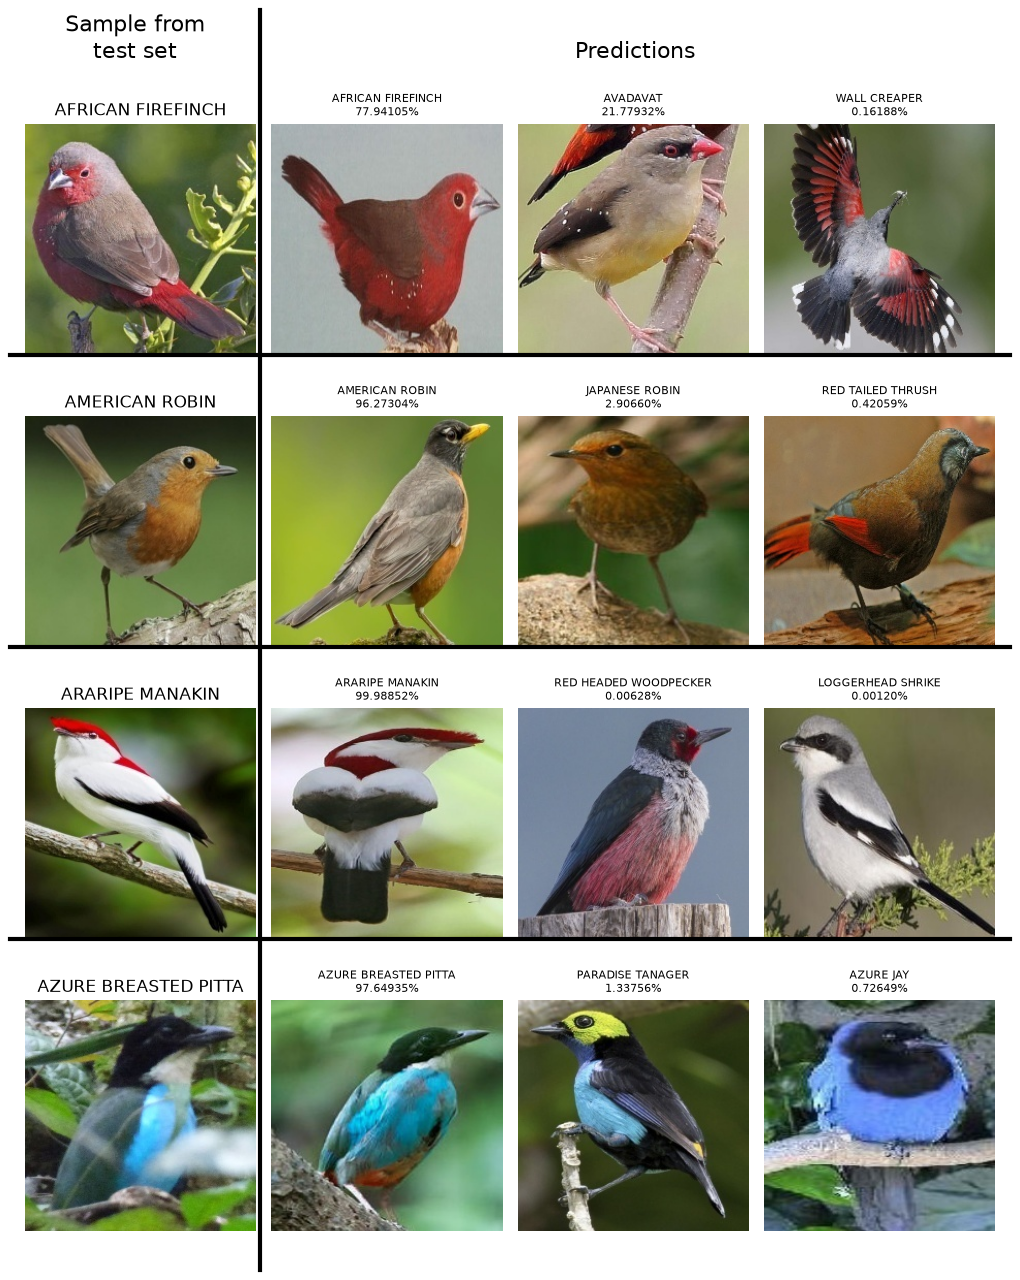

In [109]:
plot_bird_predictions(perfect_birds[:4], file_name = 'good_birds.png')

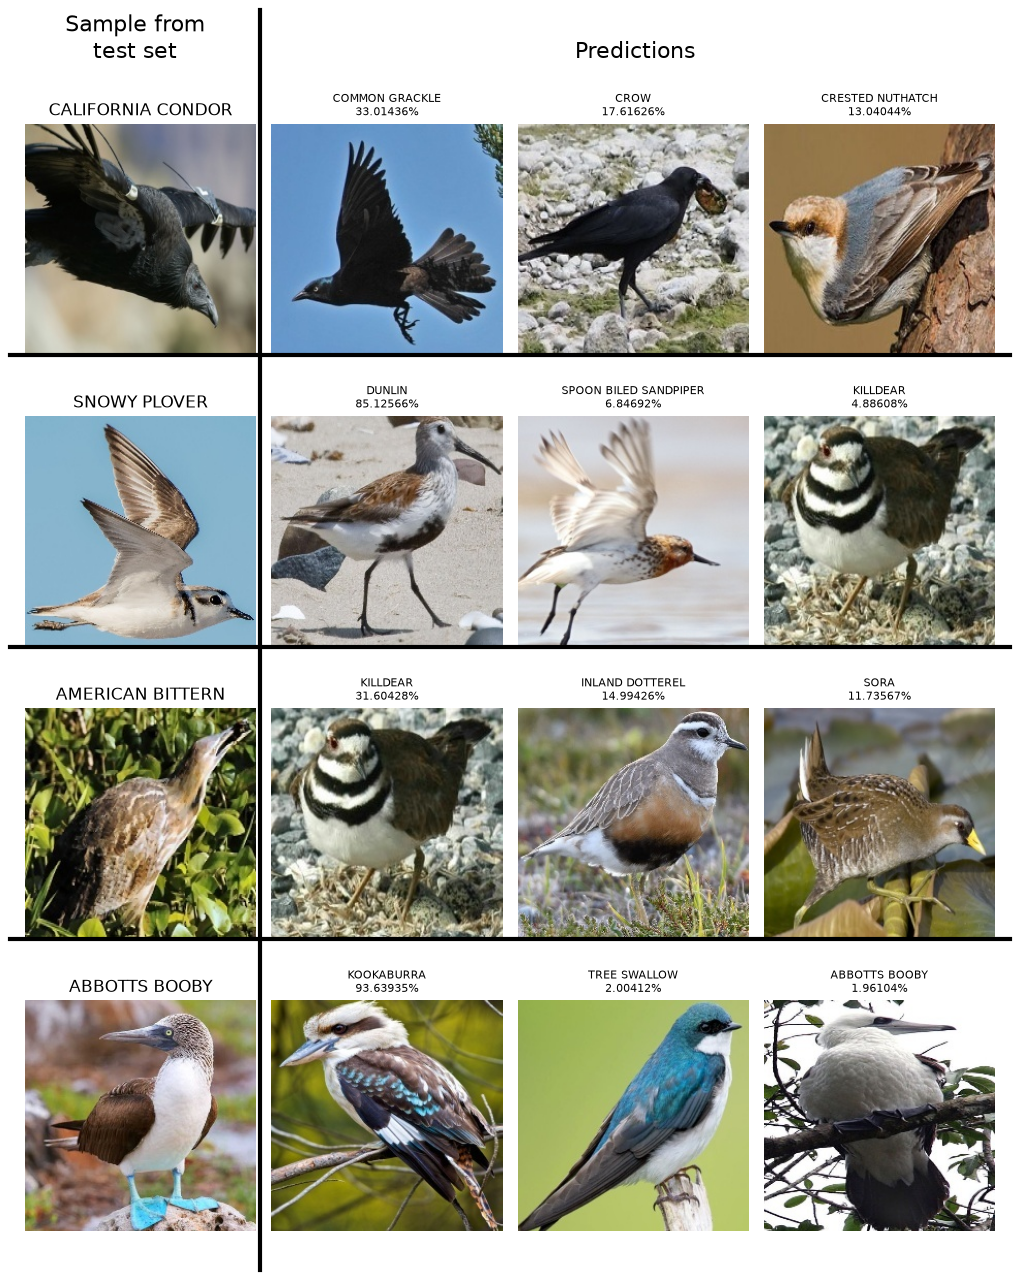

In [110]:
plot_bird_predictions(worst_birds[:4], file_name = 'bad_birds.png')